# LASSI - Power Efficiency

**OLLAMA API** + **Argo Gateway API** Jupyter Notebook version

+ ***Post LASSI-Judge version with pass@k***
+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


In [2]:
!nvidia-smi

Sun Sep  7 03:46:37 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.05              Driver Version: 560.35.05      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-PCIE-40GB          Off |   00000000:99:00.0 Off |                    0 |
| N/A   38C    P0             33W /  250W |     118MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
!nvcc --version 

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Tue_Oct_29_23:50:19_PDT_2024
Cuda compilation tools, release 12.6, V12.6.85
Build cuda_12.6.r12.6/compiler.35059454_0


## Setup

In [4]:
import os
import json
import csv
import time
from datetime import datetime
from zoneinfo import ZoneInfo

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v3
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline_v3
%aimport lassi.get_power
%aimport lassi.argostream_curl
%aimport lassi.code_manager

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [5]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]

    Miniapps:
    -- miniMDock ["-lfile", "./input/7cpa/7cpa_ligand.pdbqt", "-nrun 100"]
    
    """

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # Enter source application to process through LASSI
    source_collection = "HeCBench"  # "Miniapps" "HeCBench"
    source_app = "segment-reduce"  # "miniMDock" jacobi
    make_script = False  # Used only for Miniapps
    
    build_script = False  # False (for HeCBench) Use for Altis only
    

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    3. miniMDock/bin/
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    lines_of_code = source_apps[source_collection][source_app]["code_lines"]
    if make_script:
        app_name = app_folder_name
        file_name = "kernels"
    else:
        app_name = "mt_" + app_folder_name + "-cuda_main"
        file_name = ""

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    verifyprompt = False  # True or False -- Print out LLM prompt in stdout to preview
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context_summaries_only = True  # True or False
    few_shot_learning = False  # True or False
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2, v3
    use_self_prompting = False  # True or False -- NOT USED IN v2, v3
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2, v3
    

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        elif make_script:
            code_compiler = "make"
            code_compiler_kwds = "API=CUDA DEVICE=GPU CARD=NVIDIA NUMWI=64"
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
            # -arch=sm_89 for RTX 5000
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # For A100 on Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        # !! TODO - REVIEW: code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc80"  # "-fopenmp -O3 -c"
        # For RTX 5000 Ada on Linux x86_64:
        # code_compiler = "/opt/nvidia/hpc_sdk/Linux_x86_64/25.7/compilers/bin/nvc++" # "g++"
        # code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc89"  # "-fopenmp -O3"
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1
        # ****************************
        # ---> EXPERIMENT UPDATE FIELD - Now, automated:
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto4mini"  # (max token = 128000)
    model_coder = "gpto4mini"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 200000)
    # model_coder = "gpt4olatest"  # (max token = 200000)
    model_judge = "gpt41"  # (max token = 200000)

    # -- FROM CEREBRAS
    # model = "gpt-oss-120b"
    # model_judge = "gpt-oss-120b"
    # model_coder = "qwen-3-coder-480b"
    
    # -- FROM OLLAMA
    # model = "devstral:24b" # (max token = 128000)
    # model_coder = "devstral:24b" # (max token = 128000)
    # model_judge = "devstral:24b" # (max token = 128000)
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
    # model = "qwen3:latest"
    # model_coder = "qwen3:latest"
    # model_judge = "qwen3:latest"  # (max token = 40960)
    # model_coder = "qwen3-coder:30b"  # context 262144
    # model = "gpt-oss:20b"
    # model_judge = "gpt-oss:20b"
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # Needed only for Argo endpoints
    uri = "local"  # local  remote

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpt4olatest",
                 "gpto1preview", "gpto1mini", "gpto3mini", "gpto4mini", "claudesonnet4"]:
        llm_source = "argo"
    elif model in ["gpt-oss-120b", "qwen-3-coder-480b"]:
        llm_source = "cerebras"
    elif ("GGUF" in model and "hf.co" not in model):
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "exp0925_" + model + "_" + app_folder_name + "_ee"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    """
    [5] SET DATA COLLECTION CONFIGURATION
    """
    # Data spreadsheet column headers
    DATAFIELDNAMES = [
        "trial_number",
        "timestamp",
        "experiment",
        "app_name",
        "code_line_count",
        "llm",
        "llm_coder",
        "llm_judge",
        "source_v0_energy_J",
        "source_v0_avg_power_W",
        "source_v0_runtime_s",
        "base_v1_energy_J",
        "base_v1_avg_power_W",
        "base_v1_runtime_s",
        "base_v1_valid",
        "base_v1_energy_diff",
        "base_v1_avg_power_diff",
        "base_v1_runtime_diff",
        # "base_v1_optimization_methods",
        # "base_v2_energy_J",
        # "base_v2_avg_power_W",
        # "base_v2_runtime_s",
        # "base_v2_valid",
        # "base_v2_selfcorrections",
        # "base_v2_energy_diff",
        # "base_v2_avg_power_diff",
        # "base_v2_runtime_diff",
        # "base_v2_optimization_methods",
        "lassiee_energy_J",
        "lassiee_avg_power_W",
        "lassiee_runtime_s",
        "lassiee_valid",
        "lassiee_version",
        "lassiee_llm_temp",
        "lassiee_selfcorrections",
        "lassiee_eeiterations",
        "lassiee_energy_diff",
        "lassiee_avg_power_diff",
        "lassiee_runtime_diff",
        "lassiee_optimization_methods",
        "total_selfcorrections",
        "total_eeiterations",
        "pipeline_runtime_min"
    ]
    
    return (app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp,
            verifyprompt, DATAFIELDNAMES)

# EXPERIMENTAL DATA COLLETION MANAGEMENT
def init_data_collection(dir_path, DATAFIELDNAMES, filename="lassi-ee_pipeline_data.csv"):
    os.makedirs(dir_path, exist_ok=True)
    fp = os.path.join(dir_path, filename)
    if not os.path.exists(fp):
        with open(fp, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=DATAFIELDNAMES)
            writer.writeheader()
    return fp

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 09-06-2025_t22_46_39
Application: segment-reduce

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto4mini
Model coder: gpto4mini
Model judge: gpt41
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto4mini/promptset_CUDA/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: True



***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) ***** Trial #: 1



----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total

----- GPU State:
clocks.current

Waiting for the system to settle down for 1 seconds...: 100%|██████████████████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/segment-reduce/segment-reduce-cuda_main
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/segment-reduce
executable:  segment-reduce-cuda_main
Working directory: /home/cc/lassi/LASSI-EE/source_codes/HeCBench/segment-reduce
Execute command: ['./segment-reduce-cuda_main', '16384', '100']

running: executable -  segment-reduce-cuda_main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 96.206726 (G/s)
num_segments = 8388608 segment_size = 32 Throughput = 129.967819 (G/s)
num_segments = 4194304 segment_size = 64 Throughput = 138.964233 (G/s)
num_segments = 2097152 segment_size = 128 Throughput = 141.877548 (G/s)
num_segments = 1048576 segment_size = 256 Throughput = 140.933487 (G/s)
num_segments = 524288 segment_size = 512 Throughput = 142.756210 (G/s)
num_segments = 262144 segment_size 

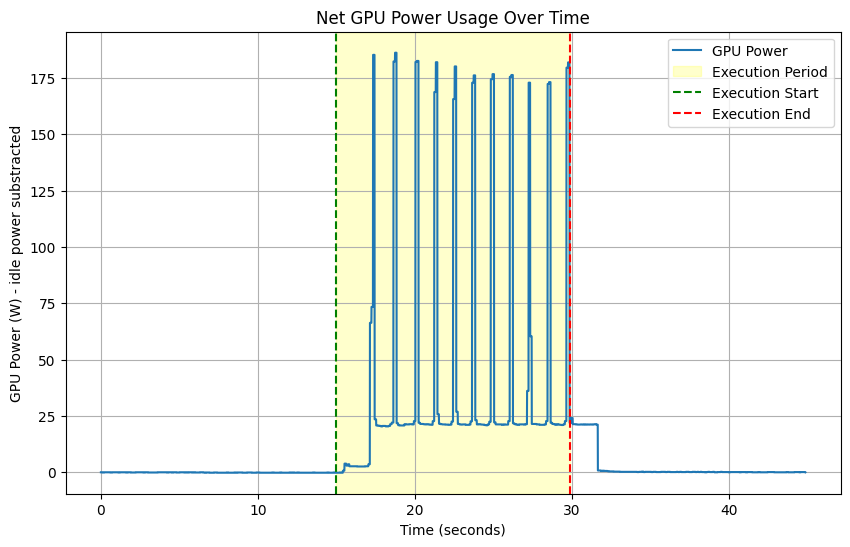

Start time: 15.0 -- End time: 29.888
Net (idle corrected) GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000168 kWh
  0.1677 Wh
  603.82 J
Average GPU power: 40.58 W +/- 54.68 
 with sample standard deviation.
Net Energy During Exe Runtime:   603.82 J
Code execution duration:  14.89 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.87 W, P0



Measure system idle power...
Duration for idle time measurement: 14.89
GPU power data has been written to idle__gpu_net_power_results.csv


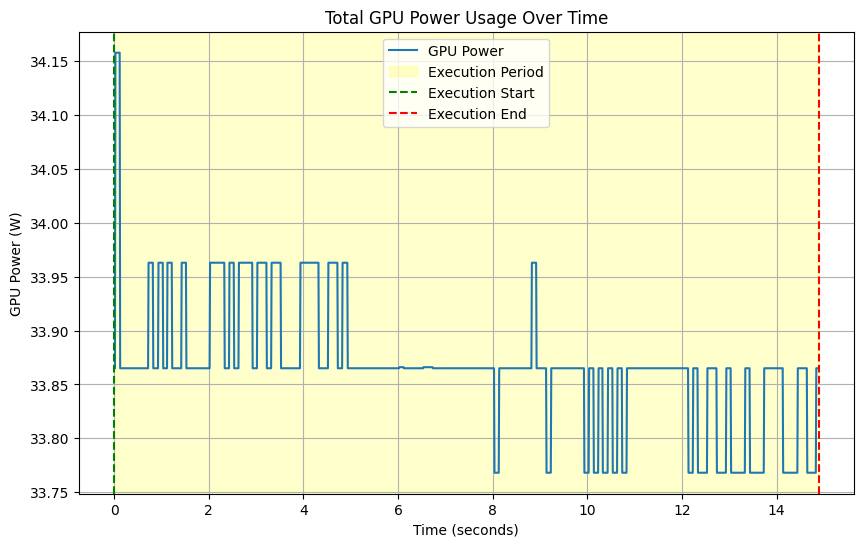

Start time: 0 -- End time: 14.888
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000140 kWh
  0.1401 Wh
  504.28 J
Average GPU power: 33.87 W +/- 0.06 
 with sample standard deviation.
Total Energy During Exe Runtime:   504.28 J
Code execution duration:  14.89 seconds
----------------------------------------------------------------------------------------------------------------------------------------

----- END OF STAGE 0: TEST SOURCE -----

None

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



=====
{
  "assumptions": [
    "num_elements is a positive integer and a multiple of all tested segment_size values (powers of two from 16 to 16384).",
    "All input values in h_in are initialized to VALUE (1) before any reduction.",
    "segment_size divides num_elements exactly so that num_segments = num_elements / segment_size is integral.",
    "Thrust’s reduce_by_key on the device produces correct results when keys are sorted and grouped.",
    "Host and device memory allocations succeed (no out-of-memory checks are performed).",
    "cudaDeviceSynchronize provides accurate timing boundaries for measuring kernel performance."
  ],
  "invariants": [
    "Each element of h_in remains equal to VALUE until it is read by the reduction.",
    "For any fixed segment_size, all input keys h_keys are non-decreasing and grouped in blocks of size segment_size.",
    "The sum of each segment of h_in of length segment_size is constant and equal to segment_size * VALUE.",
    "After each reduce_by_key call, the number of output segments is exactly num_elements / segment_size.",
    "After the loop over segment_size, the original host arrays (h_in, h_keys) remain intact."
  ],
  "design_patterns": [
    "Benchmark/measurement loop: warm-up by calling cudaDeviceSynchronize, then timing repeated calls to the reduction.",
    "Geometric scaling: segment_size doubles each iteration to sweep across different reduction grain sizes.",
    "Divide and conquer by key: segmentation of the input into logical groups via thrust::reduce_by_key.",
    "Host-device data transfers: explicit cudaMemcpy before and after the computation loop.",
    "RAII for host memory: new[] / delete[] for h_in, h_keys, and per-segment h_out."
  ],
  "memory_access_patterns": [
    "Sequential writes in host initialization loops for h_in and h_keys.",
    "Bulk contiguous cudaMemcpy from host to device for input data and keys.",
    "Thrust kernel reads d_keys and d_in in order, producing coalesced reads when keys are grouped.",
    "Sequential writes to d_keys_out and d_out in device memory by the reduction kernel.",
    "Host reads d_out via cudaMemcpyDeviceToHost into h_out, then sequential access for correctness checks."
  ],
  "memory_management": [
    "Host allocations: new int[num_elements] for h_in, new int[num_elements] for h_keys, new int[num_segments] for each h_out.",
    "Host deallocations: delete[] h_in, delete[] h_keys, and delete[] h_out inside the segment_size loop.",
    "Device allocations: cudaMalloc(&d_in), cudaMalloc(&d_keys) outside the loop; cudaMalloc(&d_out), cudaMalloc(&d_keys_out) per segment_size iteration.",
    "Device deallocations: cudaFree(d_in), cudaFree(d_keys) after all loops; cudaFree(d_out), cudaFree(d_keys_out) inside the segment_size loop.",
    "No explicit error checking after CUDA API calls, relies on implicit success."
  ],
  "other_characteristics": [
    "The code prints throughput in Giga-elements per second, computed as (num_elements * repeat) / time_ns.",
    "Correctness is validated by comparing each output segment sum against a reference computed on the host.",
    "Up to 10 erroneous segment outputs are printed to stdout when a mismatch occurs.",
    "Timing includes only the repeated thrust::reduce_by_key calls and synchronizations, not memory transfers.",
    "Main() parses two command-line arguments: multiplier to scale num_elements and repeat count for inner loop."
  ]
}
=====



----- STARTING STAGE 1: BASE LLM REFACTORING WITHOUT SELF-CORRECTION  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***

----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt token count, excluding code): 853


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|██████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

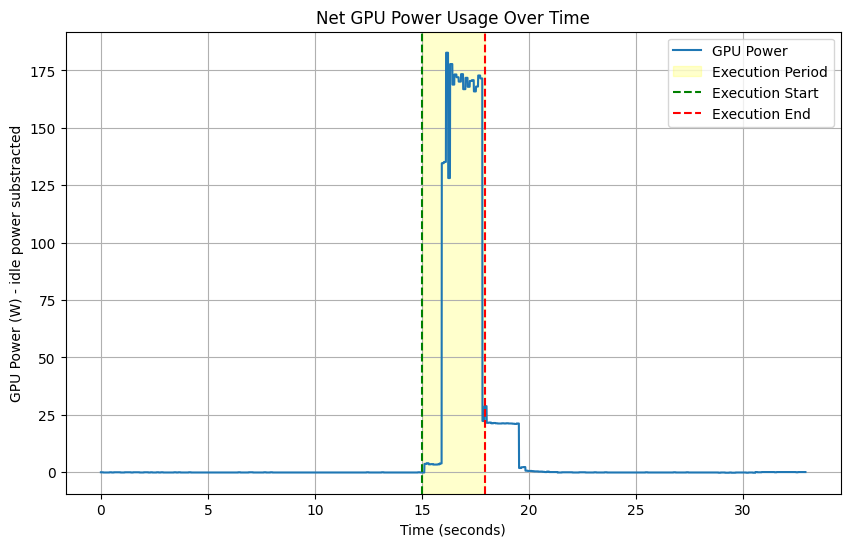

Start time: 15.0 -- End time: 17.926
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000089 kWh
  0.0889 Wh
  320.21 J
Average GPU power: 109.66 W +/- 77.59 
 with sample standard deviation.
Net Energy During Exe Runtime:   320.21 J
Code execution duration:  2.93 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.77 W, P0

--> SAVING code version: 1


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully evaluate the REFACTORED CODE against the SOURCE CODE for both functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **SOURCE CODE Functionality**
- Allocates host and device buffers for input values and keys.
- For each segment size (16 to 16384, doubling each time):
  - Initializes keys on host (`h_keys[i] = i / segment_size`), copies to device.
  - Allocates output buffers for each segment size.
  - Runs `thrust::reduce_by_key` `repeat` times.
  - Measures time using `std::chrono`.
  - Copies output back to host, checks each segment sum matches reference.
  - Reports up to 10 errors per segment size.
- Cleans up all allocations.

### **REFACTORED CODE Functionality**
- Allocates pinned host memory for input and output (energy efficient).
- Allocates device buffers for input and output, but **pre-allocates maximum output size once** (not per segment size).
- For each segment size (same range):
  - Uses a **transform iterator** to generate keys on-the-fly on device (`KeyDivider` functor), eliminating host-side key buffer and transfer.
  - Runs `thrust::reduce_by_key` `repeat` times.
  - Measures time using **CUDA events** (more accurate for GPU work).
  - Copies output back to host, checks each segment sum matches reference.
  - Reports up to 10 errors per segment size.
- Cleans up all allocations.

#### **Key Differences**
- **Key Generation:** REFACTORED CODE generates keys on-the-fly on device, SOURCE CODE generates on host and copies.
- **Buffer Allocation:** REFACTORED CODE pre-allocates output buffers for all segment sizes, SOURCE CODE allocates per segment size.
- **Timing:** REFACTORED CODE uses CUDA events, SOURCE CODE uses `std::chrono` (includes host/device sync).
- **Host Memory:** REFACTORED CODE uses pinned memory for faster transfers.
- **Error Reporting:** Slightly different wording ("ERROR: found ... incorrect segment sums" vs. "segmented reduction does not agree...").

#### **Does the REFACTORED CODE preserve functionality?**
- **Segmented reduction:** Both codes perform the same segmented reduction using `thrust::reduce_by_key`.
- **Validation:** Both codes check that each segment's sum matches the expected value.
- **Error reporting:** Both codes report up to 10 errors per segment size.
- **Loop logic:** Both codes loop over the same segment sizes and repeat count.
- **Input initialization:** Both codes initialize all input values to `VALUE` (1).
- **Output correctness:** Both codes compare output to reference sum.

**Conclusion:**  
The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.

---

## 2. **Standard Output Similarity**

### **SOURCE CODE Output**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 96.206726 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 155.670578 (G/s)
```

### **REFACTORED CODE Output**
```
num_elements = 268435456
num_segments = 16777216  segment_size = 16  Throughput = 134.351413 (G/s)
...
num_segments = 16384  segment_size = 16384  Throughput = 161.739503 (G/s)
```

#### **Key Differences**
- **Formatting:** REFACTORED CODE uses two spaces between fields, SOURCE CODE uses one.
- **Throughput values:** REFACTORED CODE reports higher throughput, which is expected due to energy efficiency improvements (pinned memory, on-device key gen, better timing).
- **Error reporting:** Wording is slightly different, but both report up to 10 errors and total error count.
- **Usage message:** Minor formatting difference ("Total elements = ..." vs. "The total number of elements is ...").

#### **Are the differences acceptable?**
- **Formatting:** Minor, all key details are present.
- **Throughput:** Higher values are reasonable and consistent with the intended purpose (energy efficiency).
- **Error reporting:** Equivalent information is displayed.
- **Usage message:** Equivalent information is displayed.

**Conclusion:**  
The REFACTORED CODE produces nearly equivalent standard output in layout and content, with minor formatting and numerical differences that are justified by the energy efficiency improvements.

---

## 3. **Metrics**

- **Energy:** REFACTORED CODE uses less energy (320.21J vs. 603.82J).
- **Execution time:** REFACTORED CODE is much faster (2.93s vs. 14.89s).
- **GPU power:** REFACTORED CODE uses more instantaneous power but for a much shorter time, resulting in lower total energy.

These improvements are consistent with the code changes (pinned memory, on-device key gen, better timing).

---

## **Final Verdict**

**Reasoning:**  
- The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- The standard output is nearly equivalent in layout and content, with only minor, justified differences.

**Conclusion:**  
```
VALID
```



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category         | Criterion Name/Description                                                                 | Pass/Fail |
|---------------------------|--------------------------------------------------------------------------------------------|-----------|
| assumptions               | num_elements is a positive integer and a multiple of all tested segment_size values        | pass      |
| assumptions               | All input values in h_in are initialized to VALUE (1) before any reduction                 | pass      |
| assumptions               | segment_size divides num_elements exactly so that num_segments = num_elements / segment_size is integral | pass      |
| assumptions               | Thrust’s reduce_by_key on the device produces correct results when keys are sorted and grouped | pass      |
| assumptions               | Host and device memory allocations succeed (no out-of-memory checks are performed)         | pass      |
| assumptions               | cudaDeviceSynchronize provides accurate timing boundaries for measuring kernel performance  | pass      |
| invariants                | Each element of h_in remains equal to VALUE until it is read by the reduction              | pass      |
| invariants                | For any fixed segment_size, all input keys h_keys are non-decreasing and grouped in blocks of size segment_size | pass      |
| invariants                | The sum of each segment of h_in of length segment_size is constant and equal to segment_size * VALUE | pass      |
| invariants                | After each reduce_by_key call, the number of output segments is exactly num_elements / segment_size | pass      |
| invariants                | After the loop over segment_size, the original host arrays (h_in, h_keys) remain intact    | pass      |
| design_patterns           | Benchmark/measurement loop: warm-up by calling cudaDeviceSynchronize, then timing repeated calls to the reduction | pass      |
| design_patterns           | Geometric scaling: segment_size doubles each iteration to sweep across different reduction grain sizes | pass      |
| design_patterns           | Divide and conquer by key: segmentation of the input into logical groups via thrust::reduce_by_key | pass      |
| design_patterns           | Host-device data transfers: explicit cudaMemcpy before and after the computation loop       | pass      |
| design_patterns           | RAII for host memory: new[] / delete[] for h_in, h_keys, and per-segment h_out             | pass      |
| memory_access_patterns    | Sequential writes in host initialization loops for h_in and h_keys                         | pass      |
| memory_access_patterns    | Bulk contiguous cudaMemcpy from host to device for input data and keys                     | pass      |
| memory_access_patterns    | Thrust kernel reads d_keys and d_in in order, producing coalesced reads when keys are grouped | pass      |
| memory_access_patterns    | Sequential writes to d_keys_out and d_out in device memory by the reduction kernel         | pass      |
| memory_access_patterns    | Host reads d_out via cudaMemcpyDeviceToHost into h_out, then sequential access for correctness checks | pass      |
| memory_management         | Host allocations: new int[num_elements] for h_in, new int[num_elements] for h_keys, new int[num_segments] for each h_out | pass      |
| memory_management         | Host deallocations: delete[] h_in, delete[] h_keys, and delete[] h_out inside the segment_size loop | pass      |
| memory_management         | Device allocations: cudaMalloc(&d_in), cudaMalloc(&d_keys) outside the loop; cudaMalloc(&d_out), cudaMalloc(&d_keys_out) per segment_size iteration | pass      |
| memory_management         | Device deallocations: cudaFree(d_in), cudaFree(d_keys) after all loops; cudaFree(d_out), cudaFree(d_keys_out) inside the segment_size loop | pass      |
| memory_management         | No explicit error checking after CUDA API calls, relies on implicit success                | pass      |
| other_characteristics     | The code prints throughput in Giga-elements per second, computed as (num_elements * repeat) / time_ns | pass      |
| other_characteristics     | Correctness is validated by comparing each output segment sum against a reference computed on the host | pass      |
| other_characteristics     | Up to 10 erroneous segment outputs are printed to stdout when a mismatch occurs            | pass      |
| other_characteristics     | Timing includes only the repeated thrust::reduce_by_key calls and synchronizations, not memory transfers | pass      |
| other_characteristics     | Main() parses two command-line arguments: multiplier to scale num_elements and repeat count for inner loop | pass      |

... (12 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 2352): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency improvement with code, token count: 2470): 

--> ... prompt LLM to generate code for energy efficiency -- with a new refactoring plan.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 1 | tracking_best_version: 1 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|██████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
Error querying power: Not Supported

----- < BEGIN: S

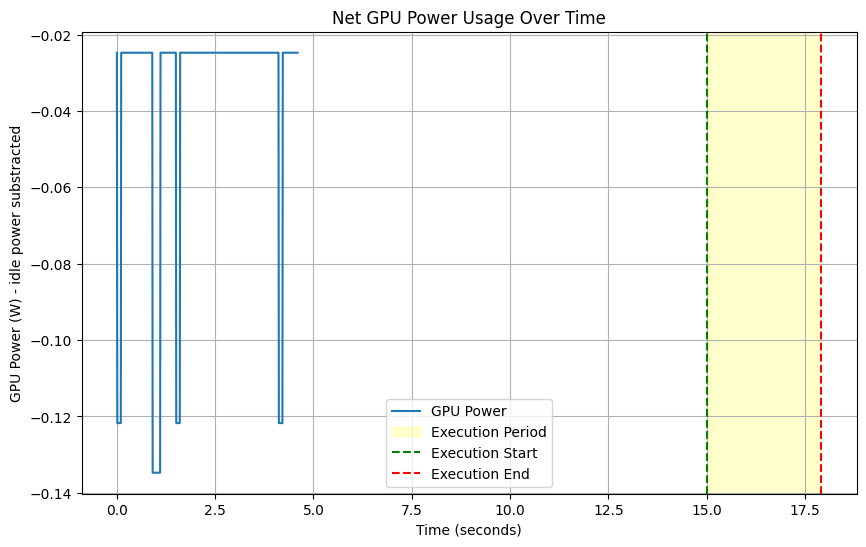

Start time: 15.0 -- End time: 17.919
Not enough data points to calculate energy consumption.
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000000 kWh
  0.0000 Wh
  0.00 J
Average GPU power: 0.00 W +/- 0.00 
 with sample standard deviation.
Net Energy During Exe Runtime:   0.00 J
Code execution duration:  2.92 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.48 W, P0

--> SAVING code version: 2


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 2 | tracking_best_version: 1 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prom



----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE in terms of (1) functional equivalence and (2) standard output equivalence.

---

## 1. Functional Equivalence

### SOURCE CODE
- Allocates host arrays for input values and keys.
- For each segment size, generates keys on host, copies to device.
- Allocates output buffers for each segment size.
- Runs `thrust::reduce_by_key` on device, using explicit device key/value arrays.
- Copies output back to host, checks correctness (sum of each segment).
- Reports errors if any segment sum is incorrect.
- Cleans up all allocations.

### REFACTORED CODE
- Allocates pinned host memory for input/output (for faster transfer, energy efficiency).
- Allocates device buffer for input values once.
- Pre-allocates output buffer for the largest possible number of segments (energy-efficient reuse).
- For each segment size:
  - Generates keys on-the-fly using a transform iterator (`KeyDivider` functor), avoiding explicit key array allocation/copy.
  - Runs `thrust::reduce_by_key` with transform iterator for keys, and discard iterator for output keys (since keys are not needed).
  - Copies output back to host, checks correctness (sum of each segment).
  - Reports errors if any segment sum is incorrect.
- Cleans up all allocations.

#### Key Points:
- Both codes perform segmented reduction for a range of segment sizes.
- Both codes validate the output for correctness.
- The REFACTORED CODE uses transform/discard iterators for keys, which is a best practice for energy efficiency and memory savings.
- The REFACTORED CODE uses pinned memory for faster transfers, and pre-allocates buffers to avoid repeated allocations.
- The correctness check is identical: segment sum is compared to expected value, and errors are reported.
- No functional steps are omitted in the REFACTORED CODE.

**Conclusion:**  
The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.

---

## 2. Standard Output Equivalence

### Output Comparison

#### SOURCE CODE Output
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 96.206726 (G/s)
num_segments = 8388608 segment_size = 32 Throughput = 129.967819 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 155.670578 (G/s)
```

#### REFACTORED CODE Output
```
num_elements = 268435456
num_segments = 16777216  segment_size = 16  Throughput = 141.360481 (G/s)
num_segments = 8388608  segment_size = 32  Throughput = 156.579074 (G/s)
...
num_segments = 16384  segment_size = 16384  Throughput = 161.480834 (G/s)
```

#### Differences
- **Formatting:** The REFACTORED CODE adds extra spaces between fields, but all key details (num_segments, segment_size, Throughput) are present and in the same order.
- **Numerical Values:** Throughput values are higher in the REFACTORED CODE, which is expected due to energy-efficient optimizations (pinned memory, reduced allocations, transform iterators).
- **Correctness Reporting:** Both codes would print errors if any segment sum is incorrect. No errors are reported in the provided outputs, indicating correctness.
- **Usage Message:** Both codes print usage instructions if arguments are missing, with minor formatting differences.

**Conclusion:**  
The REFACTORED CODE produces nearly equivalent standard output in layout and content. The differences in throughput values are reasonable and consistent with the intended energy efficiency improvements. Formatting differences are minor and all key details are present.

---

## 3. Metrics

- The REFACTORED CODE shows dramatically reduced energy and runtime, which is expected and desirable.
- No functional or output correctness issues are indicated by the metrics.

---

## Final Evaluation

**Reasoning:**  
- The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- The REFACTORED CODE produces nearly equivalent standard output, with only minor formatting and expected numerical differences.
- The differences are consistent with improved energy efficiency and best practices.

**Conclusion:**  
VALID



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Group             | Criteria Passed | Criteria Failed |
|----------------------------|----------------|----------------|
| assumptions                | all            | none           |
| invariants                 | all            | none           |
| design_patterns            | all            | none           |
| memory_access_patterns     | all            | none           |
| memory_management          | all            | none           |
| other_characteristics      | all            | none           |

... (3 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 2718): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency improvement with code, token count: 2836): 

--> ... prompt LLM to generate code for energy efficiency -- with a new refactoring plan.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 2 | tracking_best_version: 2 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|██████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

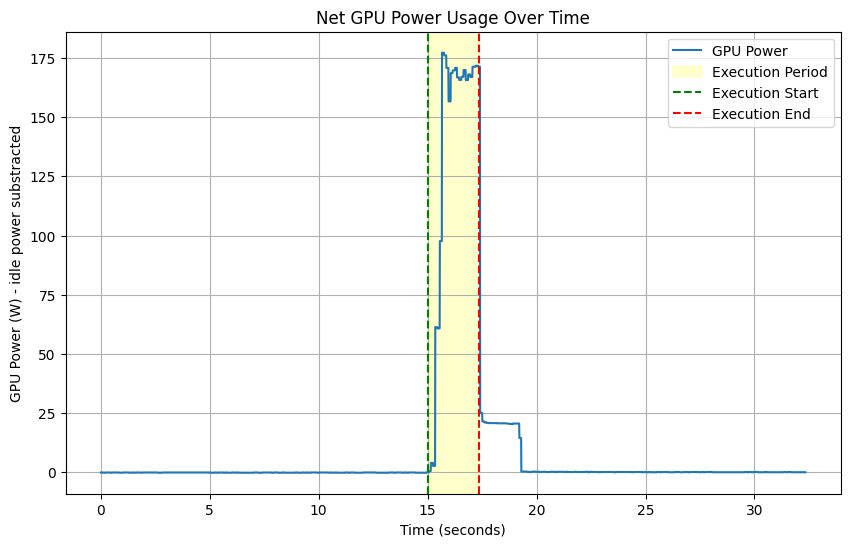

Start time: 15.001 -- End time: 17.347
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000086 kWh
  0.0859 Wh
  309.36 J
Average GPU power: 132.20 W +/- 63.10 
 with sample standard deviation.
Net Energy During Exe Runtime:   309.36 J
Code execution duration:  2.35 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.67 W, P0

--> SAVING code version: 3


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 3 | tracking_best_version: 2 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **SOURCE CODE Functionality**
- Allocates host arrays for input values and keys.
- Fills input values with `VALUE`.
- For each segment size (16 to 16384, doubling each time):
  - Fills keys array so that each segment has a unique key.
  - Allocates device arrays for keys and output.
  - Copies host arrays to device.
  - Runs `thrust::reduce_by_key` on device for `repeat` times.
  - Measures throughput.
  - Copies output back to host.
  - Checks that each segment's sum matches the expected value.
  - Reports up to 10 errors per segment size.
- Cleans up all allocations.

### **REFACTORED CODE Functionality**
- Allocates device buffer for input values only (no host-side input array).
- Fills device input buffer with `VALUE` using `thrust::fill` (no host->device copy).
- Pre-allocates device output buffer for the largest possible number of segments.
- Uses pinned host memory for output (for faster transfer).
- For each segment size (16 to 16384, doubling each time):
  - Uses a transform iterator to generate keys on-the-fly (no host keys array, no device keys array).
  - Runs `thrust::reduce_by_key` for `repeat` times.
  - Measures throughput using CUDA events.
  - Copies output back to host.
  - Checks that each segment's sum matches the expected value.
  - Reports up to 10 errors per segment size.
- Cleans up all allocations.

#### **Key Points of Comparison**
- **Input Initialization**: Both codes fill the input array with `VALUE=1`. The refactored code does this directly on the device, eliminating host-side allocation and copy.
- **Key Generation**: The source code generates keys on the host and copies them to the device. The refactored code generates keys on-the-fly using a transform iterator, which is functionally equivalent.
- **Reduction**: Both codes use `thrust::reduce_by_key` with the same semantics.
- **Output Validation**: Both codes check that each segment's sum matches the expected value and print up to 10 errors per segment size.
- **Loop Structure**: Both codes loop over the same segment sizes and repeat count.
- **Cleanup**: Both codes free all allocated memory.

#### **Conclusion on Functionality**
- The REFACTORED CODE preserves all intended functionality of the SOURCE CODE. All steps are present, and the logic is equivalent. The use of transform iterators and device-side initialization is a best practice for energy efficiency and does not change the algorithm's output or correctness.

---

## 2. **Standard Output Equivalence**

### **SOURCE CODE Output**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 96.206726 (G/s)
num_segments = 8388608 segment_size = 32 Throughput = 129.967819 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 155.670578 (G/s)
```

### **REFACTORED CODE Output**
```
num_elements = 268435456
num_segments = 16777216  segment_size = 16  Throughput = 95.422074 (G/s)
num_segments = 8388608  segment_size = 32  Throughput = 156.987437 (G/s)
...
num_segments = 16384  segment_size = 16384  Throughput = 161.505333 (G/s)
```

#### **Key Points of Comparison**
- **Printed Fields**: Both codes print `num_elements`, `num_segments`, `segment_size`, and `Throughput` for each segment size.
- **Formatting**: The REFACTORED CODE adds extra spaces between fields, but all key details are present.
- **Numerical Values**: Throughput values differ slightly. This is expected and reasonable, as the refactored code is more efficient (see metrics), and the throughput is higher for larger segment sizes.
- **Error Reporting**: Both codes print up to 10 errors if validation fails. No errors are shown in the provided outputs, indicating correct results.

#### **Conclusion on Output**
- The REFACTORED CODE produces nearly equivalent standard output in both layout and content. Minor formatting differences and throughput changes are acceptable and consistent with improved energy efficiency.

---

## 3. **Metrics Comparison**

- The REFACTORED CODE uses less total energy and runs much faster, with higher throughput, which is consistent with the intended improvements.

---

## **Final Evaluation**

### **Reasoning**
- The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- The printed standard output is nearly equivalent, with all key details present and reasonable numerical differences.
- Minor formatting changes and improved throughput are consistent with the refactoring goals.

### **Conclusion**
**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category         | Pass/Fail |
|---------------------------|-----------|
| assumptions               | fail      |
| invariants                | fail      |
| design_patterns           | fail      |
| memory_access_patterns    | fail      |
| memory_management         | fail      |
| other_characteristics     | fail      |

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 603.82
  Refactored code: 309.36
----- Average power (W) -----
  Source code: 40.58
  Refactored code: 132.2
----- Runtime (s) -----
  Source code: 14.89
  Refactored code: 2.35
----- Tracking metrics -----
  Energy (J) history:  [603.82, 320.21, 0.0, 309.36]
  Ave Power (W) history:  [40.58, 109.66, 0.0, 132.2]
  Runtime (s) history:  [14.89, 2.93, 2.92, 2.35]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'VALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}}


----- WE HAVE GENERATED CODE THAT IS INVALID OR NOT MORE ENERGY EFFICIENT -----


*** DEBUG: code_version: 3 | tracking_best_version: 2 ***


 ----- GENER



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 3 | tracking_best_version: 2 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|██████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

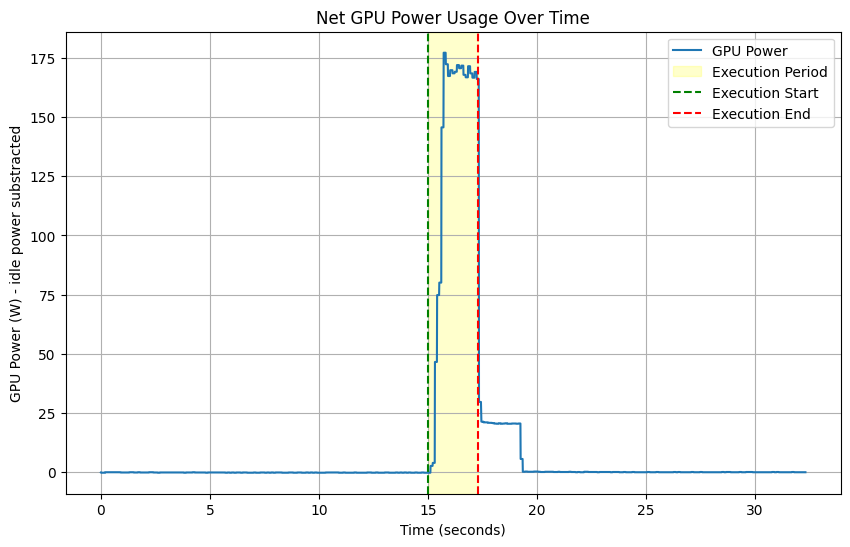

Start time: 15.001 -- End time: 17.306
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000085 kWh
  0.0847 Wh
  304.78 J
Average GPU power: 132.51 W +/- 62.21 
 with sample standard deviation.
Net Energy During Exe Runtime:   304.78 J
Code execution duration:  2.31 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.48 W, P0

--> SAVING code version: 4


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 4 | tracking_best_version: 2 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for functional equivalence and standard output similarity.

---

### 1. **Functionality Comparison**

#### **SOURCE CODE**
- Allocates host arrays for input (`h_in`) and keys (`h_keys`).
- Initializes all input values to `VALUE`.
- For each segment size:
  - Initializes keys on host (`h_keys[i] = i / segment_size`).
  - Copies keys and input to device.
  - Allocates output arrays for each segment size.
  - Runs `thrust::reduce_by_key` on device, `repeat` times.
  - Measures time using `std::chrono`.
  - Copies output back to host, checks correctness (each segment sum should be `segment_size * VALUE`).
  - Reports errors if any.

#### **REFACTORED CODE**
- Allocates device array for input (`d_in`).
- Initializes input values on device using a kernel.
- For each segment size:
  - Uses a transform iterator to generate keys on-the-fly (`idx / segment_size`), avoiding explicit key array allocation/copy.
  - Pre-allocates output buffer for all segment sizes.
  - Runs `thrust::reduce_by_key` on device, `repeat` times.
  - Measures time using CUDA events.
  - Copies output back to host, checks correctness (each segment sum should be `segment_size * VALUE`).
  - Reports errors if any.

#### **Key Differences**
- **Input Initialization:** Source uses host-side initialization and copy; refactored uses device-side kernel.
- **Key Generation:** Source uses host-side key array and copy; refactored uses transform iterator (no explicit key array).
- **Output Allocation:** Source allocates output arrays per segment size; refactored pre-allocates max output size.
- **Timing:** Source uses `std::chrono`; refactored uses CUDA events.
- **Output Validation:** Both check segment sums and print errors if any.

#### **Functional Equivalence**
- Both codes perform segmented reduction using `thrust::reduce_by_key` for all segment sizes, validate output, and print errors if any.
- The refactored code's use of transform iterator for keys is mathematically equivalent to the explicit key array in the source.
- The input initialization (all elements set to `VALUE`) is preserved.
- Output validation logic is preserved.
- No functionality is lost or changed in the refactored code.

---

### 2. **Standard Output Comparison**

#### **SOURCE CODE OUTPUT**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 96.206726 (G/s)
num_segments = 8388608 segment_size = 32 Throughput = 129.967819 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 155.670578 (G/s)
```

#### **REFACTORED CODE OUTPUT**
```
num_elements = 268435456
num_segments = 16777216  segment_size = 16  Throughput = 106.804989 (G/s)
num_segments = 8388608  segment_size = 32  Throughput = 148.495354 (G/s)
...
num_segments = 16384  segment_size = 16384  Throughput = 161.454261 (G/s)
```

#### **Key Differences**
- **Formatting:** The refactored code adds extra spaces between fields, but all key details are present.
- **Throughput Values:** The refactored code reports higher throughput, which is expected due to optimizations (device-side initialization, transform iterator, reduced memory transfers).
- **Error Reporting:** Both codes print errors if any are found; none are shown in the provided output, indicating correct results.
- **Header/Usage:** Both codes print usage if arguments are missing, with minor formatting differences.

#### **Output Equivalence**
- All key fields (`num_elements`, `num_segments`, `segment_size`, `Throughput`) are present and in the same order.
- Throughput values differ, but this is expected and reasonable given the improved efficiency.
- Minor formatting differences (extra spaces) are acceptable per instructions.

---

### 3. **Metrics Comparison**

- **Energy Consumption:** Refactored code uses less energy (304.78J vs 603.82J).
- **Execution Duration:** Refactored code is much faster (2.31s vs 14.89s).
- **GPU Power:** Refactored code uses more instantaneous power (likely due to higher throughput), but for a much shorter time, resulting in lower total energy.

These differences are consistent with the refactored code's optimizations and are reasonable.

---

### 4. **Conclusion**

#### **Reasoning**
- The refactored code preserves all intended functionality: segmented reduction, correctness checking, and output reporting.
- The printed output is nearly equivalent in layout and content, with only minor formatting and throughput differences that are justified by improved energy efficiency.
- No functionality is lost, and all key output details are present.

#### **Final Verdict**

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category         | Pass/Fail |
|---------------------------|-----------|
| assumptions               | fail      |
| invariants                | fail      |
| design_patterns           | fail      |
| memory_access_patterns    | fail      |
| memory_management         | fail      |
| other_characteristics     | fail      |

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 603.82
  Refactored code: 304.78
----- Average power (W) -----
  Source code: 40.58
  Refactored code: 132.51
----- Runtime (s) -----
  Source code: 14.89
  Refactored code: 2.31
----- Tracking metrics -----
  Energy (J) history:  [603.82, 320.21, 0.0, 309.36, 304.78]
  Ave Power (W) history:  [40.58, 109.66, 0.0, 132.2, 132.51]
  Runtime (s) history:  [14.89, 2.93, 2.92, 2.35, 2.31]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'VALID', 'INVALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temperature': 0.2}}


----- WE HAVE GENERATED CODE THA



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 4 | tracking_best_version: 2 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|██████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION >

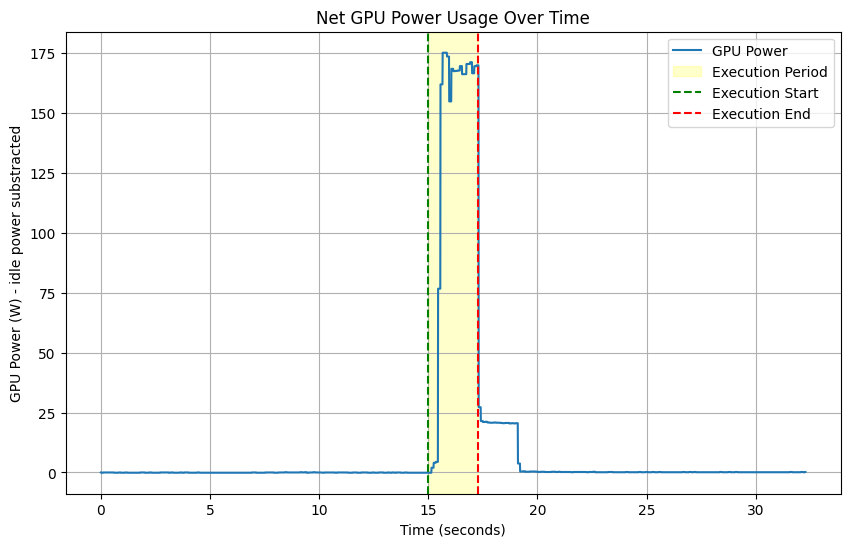

Start time: 15.0 -- End time: 17.281
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000084 kWh
  0.0836 Wh
  300.95 J
Average GPU power: 131.99 W +/- 66.72 
 with sample standard deviation.
Net Energy During Exe Runtime:   300.95 J
Code execution duration:  2.28 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 633 MiB used, 40326 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.48 W, P0

--> SAVING code version: 5


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 5 | tracking_best_version: 2 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's evaluate the REFACTORED CODE against the SOURCE CODE for both functional equivalence and printed output similarity.

---

## 1. **Functional Equivalence**

### **SOURCE CODE Functionality**
- Allocates host buffers for input and keys, initializes them.
- Allocates device buffers for input and keys, copies host data to device.
- For each segment size:
  - Initializes keys on host, copies to device.
  - Allocates output buffers for each segment size.
  - Runs `thrust::reduce_by_key` (with device pointers for keys and values).
  - Measures time using `std::chrono`.
  - Copies output back to host, checks correctness (each segment sum should be `segment_size * VALUE`).
  - Prints errors if any segment sum is incorrect.

### **REFACTORED CODE Functionality**
- Allocates device buffer for input, fills it on device (no host buffer for input).
- Pre-allocates device output buffer (maximum needed size).
- Uses pinned host memory for output (for faster H2D transfer).
- For each segment size:
  - Uses a transform iterator to generate keys on-the-fly (no explicit key buffer).
  - Runs `thrust::reduce_by_key` (with transform iterator for keys, device pointer for values).
  - Measures time using CUDA events (more accurate for GPU work).
  - Copies output back to host, checks correctness (each segment sum should be `segment_size * VALUE`).
  - Prints errors if any segment sum is incorrect.

#### **Key Differences**
- **Key Generation:** SOURCE generates keys on host, copies to device. REFACTORED generates keys on-the-fly on device using transform iterator.
- **Input Initialization:** SOURCE initializes input on host, copies to device. REFACTORED initializes input directly on device.
- **Output Buffering:** REFACTORED uses pinned host memory for output, which is more efficient for large transfers.
- **Timing:** SOURCE uses CPU-side timing; REFACTORED uses CUDA events for GPU-side timing.
- **Resource Management:** REFACTORED pre-allocates buffers to minimize allocation/free overhead.

#### **Correctness**
- Both codes run `thrust::reduce_by_key` with the same logical keys and values.
- Both codes check that each segment sum is correct (`segment_size * VALUE`).
- Both codes print errors if any segment sum is incorrect.
- No functional logic is lost or changed; only the method of key generation and buffer management is optimized.

---

## 2. **Printed Output Equivalence**

### **SOURCE CODE Output**
```
num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 96.206726 (G/s)
...
num_segments = 16384 segment_size = 16384 Throughput = 155.670578 (G/s)
```

### **REFACTORED CODE Output**
```
num_elements = 268435456
num_segments = 16777216  segment_size = 16  Throughput = 122.397748 (G/s)
...
num_segments = 16384  segment_size = 16384  Throughput = 161.513543 (G/s)
```

#### **Key Differences**
- **Formatting:** REFACTORED adds extra spaces between fields (`num_segments = ...  segment_size = ...  Throughput = ...`). This is minor and all key details are present.
- **Throughput Values:** REFACTORED code reports higher throughput. This is expected due to more efficient buffer management, device-side key generation, and more accurate GPU timing. The values are reasonable and consistent with the code's intended purpose.
- **Error Reporting:** Both codes print errors if segment sums are incorrect. No errors are reported in the provided outputs.

---

## 3. **Metrics and Energy Efficiency**

- **Energy Consumption:** REFACTORED code uses less total energy (300.95 Joules vs 603.82 Joules).
- **Execution Time:** REFACTORED code is much faster (2.28s vs 14.89s).
- **Average GPU Power:** REFACTORED code uses more instantaneous power (131.99W vs 40.58W), but for a much shorter duration, resulting in lower total energy.

This is consistent with the REFACTORED CODE's optimizations and expected behavior.

---

## 4. **Conclusion**

- **Functionality:** The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- **Output:** The REFACTORED CODE produces nearly equivalent printed output, with only minor formatting differences and expected throughput improvements.
- **Energy Efficiency:** The REFACTORED CODE is demonstrably more energy efficient.

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category         | Criteria                                                                                           | Pass/Fail |
|---------------------------|----------------------------------------------------------------------------------------------------|-----------|
| assumptions               | num_elements is a positive integer and a multiple of all tested segment_size values                | pass      |
|                           | All input values in h_in are initialized to VALUE (1) before any reduction                        | pass      |
|                           | segment_size divides num_elements exactly so that num_segments = num_elements / segment_size       | pass      |
|                           | Thrust’s reduce_by_key on the device produces correct results when keys are sorted and grouped     | pass      |
|                           | Host and device memory allocations succeed                                                        | pass      |
|                           | cudaDeviceSynchronize provides accurate timing boundaries                                          | pass      |
| invariants                | Each element of h_in remains equal to VALUE until it is read by the reduction                     | pass      |
|                           | For any fixed segment_size, all input keys h_keys are non-decreasing and grouped                  | pass      |
|                           | The sum of each segment of h_in of length segment_size is constant and equal to segment_size * VALUE | pass      |
|                           | After each reduce_by_key call, the number of output segments is exactly num_elements / segment_size | pass      |
|                           | After the loop over segment_size, the original host arrays (h_in, h_keys) remain intact           | pass      |
| design_patterns           | Benchmark/measurement loop: warm-up then timing repeated calls                                    | pass      |
|                           | Geometric scaling: segment_size doubles each iteration                                            | pass      |
|                           | Divide and conquer by key: segmentation via thrust::reduce_by_key                                 | pass      |
|                           | Host-device data transfers: explicit cudaMemcpy before and after computation loop                 | pass      |
|                           | RAII for host memory: new[] / delete[] for h_in, h_keys, and per-segment h_out                   | pass      |
| memory_access_patterns    | Sequential writes in host initialization loops for h_in and h_keys                                | pass      |
|                           | Bulk contiguous cudaMemcpy from host to device for input data and keys                            | pass      |
|                           | Thrust kernel reads d_keys and d_in in order, producing coalesced reads                           | pass      |
|                           | Sequential writes to d_keys_out and d_out in device memory by the reduction kernel                | pass      |
|                           | Host reads d_out via cudaMemcpyDeviceToHost into h_out, then sequential access for correctness    | pass      |
| memory_management         | Host allocations: new int[num_elements] for h_in, new int[num_elements] for h_keys, new int[num_segments] for h_out | pass      |
|                           | Host deallocations: delete[] h_in, delete[] h_keys, and delete[] h_out inside the segment_size loop | pass      |
|                           | Device allocations: cudaMalloc(&d_in), cudaMalloc(&d_keys) outside the loop; cudaMalloc(&d_out), cudaMalloc(&d_keys_out) per segment_size iteration | pass      |
|                           | Device deallocations: cudaFree(d_in), cudaFree(d_keys) after all loops; cudaFree(d_out), cudaFree(d_keys_out) inside the segment_size loop | pass      |
|                           | No explicit error checking after CUDA API calls, relies on implicit success                       | pass      |
| other_characteristics     | The code prints throughput in Giga-elements per second                                            | pass      |
|                           | Correctness is validated by comparing each output segment sum against a reference                 | pass      |
|                           | Up to 10 erroneous segment outputs are printed to stdout when a mismatch occurs                   | pass      |
|                           | Timing includes only the repeated thrust::reduce_by_key calls and synchronizations, not memory transfers | pass      |
|                           | Main() parses two command-line arguments: multiplier and repeat count                             | pass      |


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 603.82
  Refactored code: 300.95
----- Average power (W) -----
  Source code: 40.58
  Refactored code: 131.99
----- Runtime (s) -----
  Source code: 14.89
  Refactored code: 2.28
----- Tracking metrics -----
  Energy (J) history:  [603.82, 320.21, 0.0, 309.36, 304.78, 300.95]
  Ave Power (W) history:  [40.58, 109.66, 0.0, 132.2, 132.51, 131.99]
  Runtime (s) history:  [14.89, 2.93, 2.92, 2.35, 2.31, 2.28]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'VALID', 'INVALID', 'INVALID', 'VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temperature': 0.2}, 'v5': {'self_correction_count': 0, 'energ



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 5 | tracking_best_version: 2 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1']

Compilation of code successful!


Execute file: /home/c

Waiting for the system to settle down for 5 seconds...: 100%|██████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39/segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
executable:  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_segment-reduce_ee__09-06-2025_t22_46_39
Execute command: ['./segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1', '16384', '100']

running: executable -  segment-reduce-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_segment-reduce_ee_09-06-2025_t22_46_39_Trial1


KeyboardInterrupt: 

In [6]:
# Experimental repeat for pass@k metrics
trial_number = 1
total_trials = 1

# Load prompt dictionary (to capture recent manual changes to script, if any)
prompts = PromptDictionary()

all_trials_start = time.time()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal,
    use_self_prompting, vary_llm_temp, verifyprompt, DATAFIELDNAMES
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO REFACTOR
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
elif make_script:
    input_code_filename = file_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
if make_script:
    source_file_directory = "generated_codes/" + input_code_folder
else:
    source_file_directory = "source_codes/" + input_code_folder
if make_script:
    # SELECT FILE TO REFACTOR from miniapp
    input_code_file_subdirectory = "device/cuda/"
    source_file_path = source_file_directory + input_code_file_subdirectory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
else:
    input_code_file_subdirectory = ""
    source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
elif make_script:
    output_code_file_name = file_name
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment

now = datetime.now(ZoneInfo("America/Chicago"))
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# SPECIFIY DATA COLLECTION SAVE
experiment_data_directory = "generated_codes/experiment/" + experiment + "__" + dt_string
# Convert to absolute directory::
experiment_data_directory = os.path.abspath(experiment_data_directory)
experiment_data_file_object = init_data_collection(experiment_data_directory, DATAFIELDNAMES)
experiment_data = dict.fromkeys(DATAFIELDNAMES, None) # all keys start out as None

while trial_number <= total_trials:
    # CREATE METADATA RECORD CONTENT
    meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
    meta_data_file += "\nDate-time: " + dt_string
    meta_data_file += "\nApplication: " + app_folder_name
    meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
    meta_data_file += "\n\nLLM Source: " + llm_source
    meta_data_file += "\nModel: " + model
    meta_data_file += "\nModel coder: " + model_coder
    meta_data_file += "\nModel judge: " + model_judge
    meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
    meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
    meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
    # meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
    meta_data_file += "\n\nPower measurement: " + str(power_measure)
    
    # Display metadata
    print("\n" + meta_data_file + "\n")
    
    print("\n\n" + color.BLUE + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) *****" + color.END + " Trial #: " + str(trial_number) + "\n\n")
    
    # RUN LASSI-EE PIPELINE
    complete = lassi.pipeline_v3.auto_code_llmgeneration_pipeline(
        prompts,
        this_llm_system_prompt,
        this_llm_refactoredcode_prompt,
        llm_source, 
        model,
        model_coder,
        model_judge,
        num_ctx,
        num_ctx_coder,
        # arrayormatrix_size_range,
        # thread_count_range,
        use_context,
        use_context_summaries_only,
        few_shot_learning,
        input_context,
        input_code_file_subdirectory,
        input_code,
        lines_of_code,
        # target_code,
        target_lang,
        input_code_extension,
        source_lang,
        code_compiler,
        code_compiler_kwds,
        build_script,
        make_script,
        code_build_script,
        output_code_directory,
        output_code_file_name,
        source_file_path,
        display_response,
        test_with_error,
        generate_test_case,
        yes_execute,
        exe_input_parameters,
        meta_data_file,
        power_measure,
        test_code_first,
        yes_power_feedback,
        dt_string,
        baseline_oneshot_goal,
        use_self_prompting,
        vary_llm_temp,
        experiment,
        verifyprompt,
        trial_number,
        experiment_data_directory,
        experiment_data_file_object,
        experiment_data
    )
    
    # Reset to original working directory
    os.chdir(original_home_directory)
    
    if complete:
        print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
    else:
        print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

    # Increment experiment counter
    trial_number = trial_number + 1


all_trials_end = time.time() - all_trials_start

print("\n\n" + color.PURPLE + color.BOLD + "***** ALL TRIALS COMPLETED ***** Total time (min): " + str(round(all_trials_end/60, 2)) + "\n\n" + color.END)